# Predicting Median Graduate Student Debt — College Scorecard

**Mission & problem.** Make higher education financially transparent so students are not trapped by debt.
**Use case.** Given an institution's profile (cost, size, aid mix, outcomes), predict the **median federal loan debt of its graduates** (`GRAD_DEBT_MDN`, USD).
**Who uses it.** Prospective students and families comparing schools, and college advisors / policymakers flagging institutions whose debt burden is out of line with their profile.

**Dataset.** U.S. Department of Education *College Scorecard — Most Recent Cohorts, Institution level* (6,272 institutions × 3,379 columns). Source: https://collegescorecard.ed.gov/data/

## 1. Load candidate columns
The raw file has 3,379 columns; we load only a candidate set chosen from the Scorecard data dictionary. Scorecard marks small-cohort values as `PrivacySuppressed`, which we treat as missing.

In [1]:
import numpy as np
import pandas as pd

RAW = "Most-Recent-Cohorts-Institution.csv"
TARGET = "GRAD_DEBT_MDN"
CANDIDATES = [TARGET, "CONTROL", "PREDDEG", "REGION", "LOCALE", "STABBR",
              "ADM_RATE", "SAT_AVG", "C150_4", "RET_FT4", "COSTT4_A",
              "UGDS", "TUITIONFEE_IN", "TUITIONFEE_OUT", "PCTPELL", "PCTFLOAN",
              "UG25ABV", "INEXPFTE", "MD_EARN_WNE_P10", "AVGFACSAL"]

raw = pd.read_csv(RAW, usecols=CANDIDATES, low_memory=False).replace("PrivacySuppressed", np.nan)
num_cols = [c for c in CANDIDATES if c != "STABBR"]
raw[num_cols] = raw[num_cols].apply(pd.to_numeric, errors="coerce")
raw = raw[raw[TARGET].notna()]
print(raw.shape)
raw.isna().mean().sort_values(ascending=False).round(2)

(4776, 20)


SAT_AVG            0.79
ADM_RATE           0.65
RET_FT4            0.61
C150_4             0.58
COSTT4_A           0.42
AVGFACSAL          0.35
TUITIONFEE_OUT     0.35
TUITIONFEE_IN      0.35
UG25ABV            0.10
UGDS               0.10
INEXPFTE           0.09
PCTPELL            0.09
PCTFLOAN           0.09
LOCALE             0.09
MD_EARN_WNE_P10    0.05
STABBR             0.00
REGION             0.00
CONTROL            0.00
PREDDEG            0.00
GRAD_DEBT_MDN      0.00
dtype: float64

## 2. Feature selection — what we drop and why

| Dropped | Reason |
|---|---|
| IDs, names, URLs, ~3,350 other columns | identifiers / irrelevant / not in candidate set |
| Every other debt column (`DEBT_MDN`, `GRAD_DEBT_MDN10YR`, repayment rates…) | **target leakage** — they are the target in another form |
| `ADM_RATE`, `SAT_AVG`, `C150_4`, `RET_FT4`, `COSTT4_A` | 42–79 % missing; would shrink the data below a useful size |
| `TUITIONFEE_OUT` | near-duplicate of `TUITIONFEE_IN` (multicollinear) |
| `LOCALE`, `STABBR` | high-cardinality geography already summarised by `REGION` |

**Kept (11 features):** numeric — `UGDS` (enrolment), `TUITIONFEE_IN`, `PCTPELL`, `PCTFLOAN`, `UG25ABV` (share of students over 25), `INEXPFTE` (instructional spend per student), `MD_EARN_WNE_P10` (median earnings 10 yrs after entry), `AVGFACSAL`; categorical — `CONTROL` (1 public, 2 private non-profit, 3 for-profit), `PREDDEG` (predominant degree 1–3), `REGION` (0–9).

In [2]:
NUMERIC = ["UGDS", "TUITIONFEE_IN", "PCTPELL", "PCTFLOAN", "UG25ABV",
           "INEXPFTE", "MD_EARN_WNE_P10", "AVGFACSAL"]
CATEGORICAL = ["CONTROL", "PREDDEG", "REGION"]
FEATURES = NUMERIC + CATEGORICAL

df = raw[FEATURES + [TARGET]].dropna()
df = df[df["PREDDEG"].between(1, 3) & df["REGION"].between(1, 9)]  # drop 'not classified' / service-academy codes
df[CATEGORICAL + ["UGDS"]] = df[CATEGORICAL + ["UGDS"]].astype(int)
print(df.shape)
assert len(df) >= 1000 and len(FEATURES) >= 8 and df.isna().sum().sum() == 0
df.describe().T

(2699, 12)


,count,mean,std,min,25%,50%,75%,max
UGDS,2699.0,4827.963320,8648.216031,1.0000,841.00000,1958.0000,5116.5000,163164.0
TUITIONFEE_IN,2699.0,20522.631345,18419.597160,1104.0000,6260.00000,13641.0000,31933.5000,75162.0
PCTPELL,2699.0,0.401974,0.175084,0.0018,0.27465,0.3758,0.4890,1.0
PCTFLOAN,2699.0,0.391440,0.250103,0.0000,0.16470,0.3828,0.5864,1.0
UG25ABV,2699.0,0.247027,0.223914,0.0005,0.07340,0.1847,0.3314,1.0
INEXPFTE,2699.0,10699.997406,9515.685189,200.0000,6184.00000,8671.0000,12398.5000,181929.0
MD_EARN_WNE_P10,2699.0,55399.699889,16514.101066,20666.0000,44124.00000,51652.0000,63476.0000,166642.0
AVGFACSAL,2699.0,8470.645795,2809.423430,729.0000,6628.50000,8043.0000,9787.0000,25354.0
CONTROL,2699.0,1.603927,0.665689,1.0000,1.00000,2.0000,2.0000,3.0
PREDDEG,2699.0,2.457947,0.737630,1.0000,2.00000,3.0000,3.0000,3.0


## 3. Save the cleaned subset
The raw CSV (102 MB) exceeds GitHub's limit, so we commit this small cleaned file. The API's `/retrain` endpoint reuses it as the original training data.

In [3]:
df.to_csv("../API/debt_data.csv", index=False)
pd.read_csv("../API/debt_data.csv").head()

,UGDS,TUITIONFEE_IN,PCTPELL,PCTFLOAN,UG25ABV,INEXPFTE,MD_EARN_WNE_P10,AVGFACSAL,CONTROL,PREDDEG,REGION,GRAD_DEBT_MDN
0,6124,10558.0,0.6419,0.7714,0.0707,7254.0,41266.0,8699.0,1,3,5,27204.0
1,11635,9812.0,0.3885,0.4100,0.1656,17855.0,59631.0,12612.0,1,3,5,21250.0
2,6591,12458.0,0.2781,0.3316,0.1511,9877.0,72098.0,10639.0,1,3,5,20550.0
3,3477,11248.0,0.7197,0.7895,0.0692,10723.0,40585.0,8153.0,1,3,5,28197.0
4,33227,12484.0,0.2147,0.3528,0.0601,9728.0,66081.0,11419.0,1,3,5,21500.0


## 4. Exploratory plots

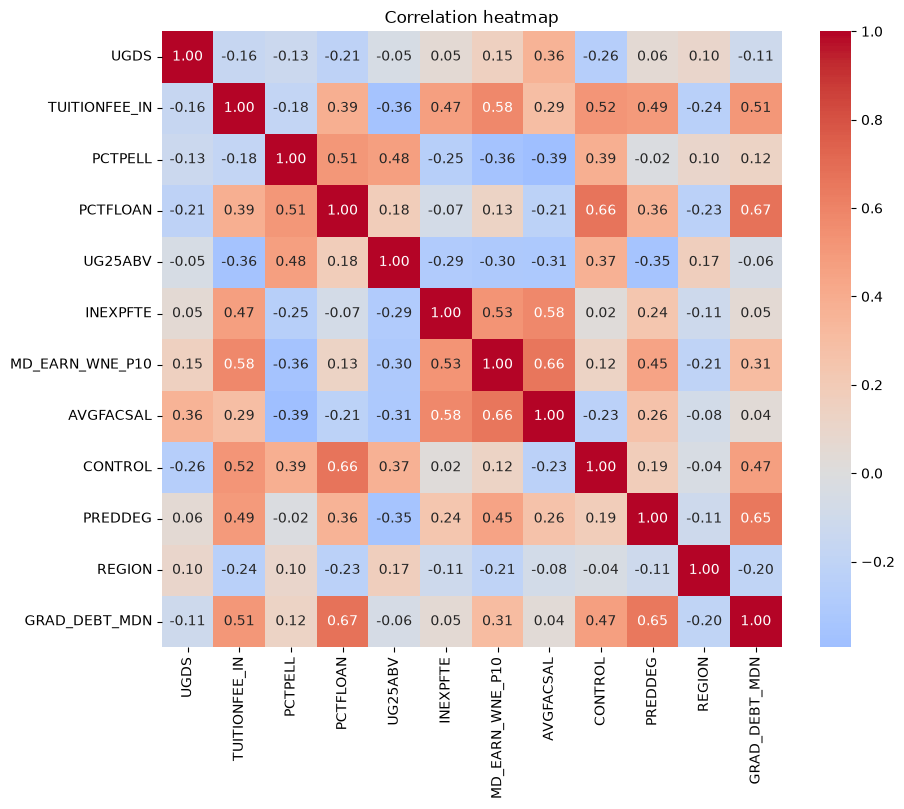

PCTFLOAN           0.672548
PREDDEG            0.646202
TUITIONFEE_IN      0.510839
CONTROL            0.469721
MD_EARN_WNE_P10    0.310450
PCTPELL            0.124990
INEXPFTE           0.052704
AVGFACSAL          0.036316
UG25ABV           -0.058749
UGDS              -0.107306
REGION            -0.199368
Name: GRAD_DEBT_MDN, dtype: float64

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.show()
df.corr()[TARGET].drop(TARGET).sort_values(ascending=False)

**What it shows.** Graduate debt is most correlated with `PCTFLOAN` (share of students borrowing, ≈0.67), `PREDDEG` (≈0.65 — bachelor's schools graduate students with more debt than certificate schools), `TUITIONFEE_IN` (≈0.51) and `CONTROL` (≈0.47). `UGDS`, `AVGFACSAL`, `INEXPFTE` and `UG25ABV` are close to zero linearly.
**Decision.** `PCTFLOAN` is the feature used for the one-feature scatter plots. Features with weak linear correlation are **kept** because tree models can use non-linear effects; no pair of features is so correlated (>0.9) that one must be dropped. `CONTROL`, `PREDDEG` and `REGION` are codes, not quantities, so they are one-hot encoded rather than treated as numbers.

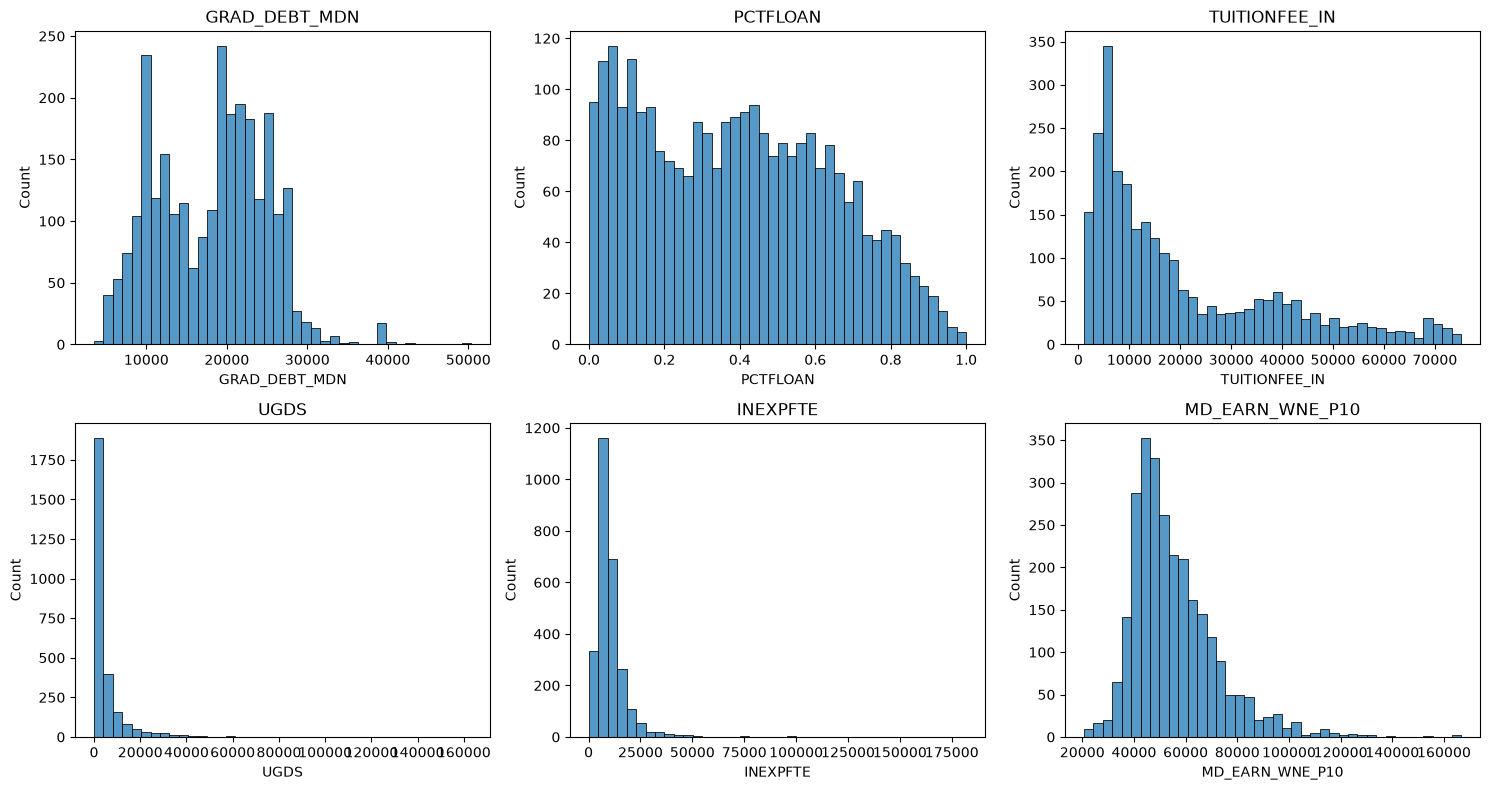

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, [TARGET, "PCTFLOAN", "TUITIONFEE_IN", "UGDS", "INEXPFTE", "MD_EARN_WNE_P10"]):
    sns.histplot(df[col], bins=40, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

**What it shows.** The target is roughly bimodal (a peak near \$9–10k for certificate/associate schools and near \$20–27k for bachelor's schools) and stays within \$3.5k–\$50k, so no outlier removal is needed. `UGDS` and `INEXPFTE` are extremely right-skewed (a few huge universities / very rich schools), and features differ in scale by 5 orders of magnitude.
**Decision.** Standardise all numeric features (essential for the gradient-descent `SGDRegressor`, which is sensitive to scale). The skew and the bimodal shape tied to `PREDDEG` suggest non-linear models (trees) may beat the linear ones.

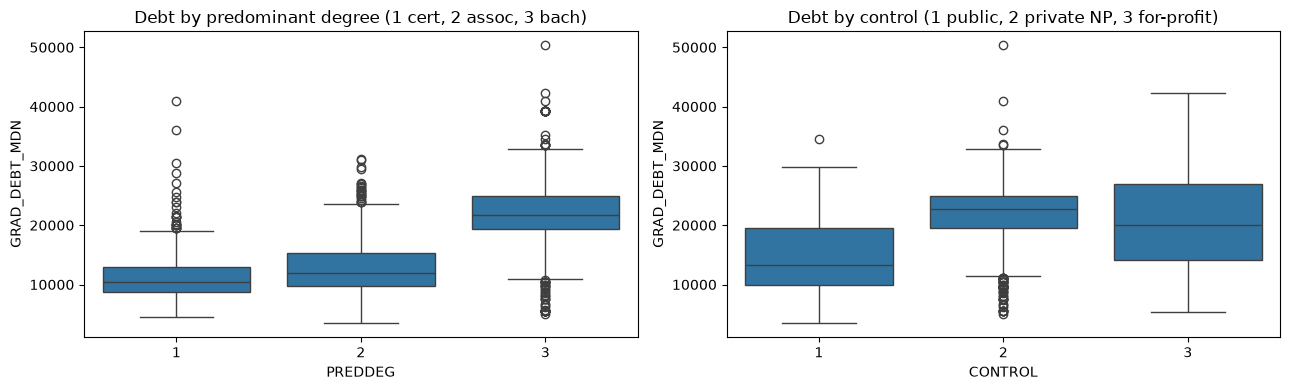

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="PREDDEG", y=TARGET, ax=axes[0]); axes[0].set_title("Debt by predominant degree (1 cert, 2 assoc, 3 bach)")
sns.boxplot(data=df, x="CONTROL", y=TARGET, ax=axes[1]); axes[1].set_title("Debt by control (1 public, 2 private NP, 3 for-profit)")
plt.tight_layout(); plt.show()

**What it shows.** Median debt rises sharply from certificate to bachelor's schools, and private/for-profit schools sit above public ones.
**Decision.** These categorical columns carry strong signal, so they are kept and one-hot encoded; the most important features overall are `PCTFLOAN`, `PREDDEG`, `TUITIONFEE_IN` and `CONTROL`.

## 5. Train/test split and preprocessing
80/20 split. The `ColumnTransformer` standardises numeric columns and one-hot encodes categorical ones. It lives inside each model's `Pipeline`, so the scaler is **fit on the training set only** and the saved model carries its own preprocessing.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ])

pre = preprocessor().fit(X_train)          # fit on train only
Xtr, Xte = pre.transform(X_train), pre.transform(X_test)
print(X_train.shape, X_test.shape, "->", Xtr.shape)

(2159, 11) (540, 11) -> (2159, 23)


## 6. Model 1 — Linear regression by gradient descent (`SGDRegressor`), tuned
Grid over learning rate `eta0`, L2 regularisation `alpha` and number of epochs. Each configuration is trained with `partial_fit` one epoch at a time.

In [8]:
from sklearn.linear_model import SGDRegressor
import itertools

def train_sgd(eta0, alpha, epochs, record=False):
    m = SGDRegressor(eta0=eta0, alpha=alpha, learning_rate="constant", penalty="l2", random_state=42)
    hist = []
    for _ in range(epochs):
        m.partial_fit(Xtr, y_train)
        if record:
            hist.append((mean_squared_error(y_train, m.predict(Xtr)), mean_squared_error(y_test, m.predict(Xte))))
    return m, hist

rows = []
for eta0, alpha, epochs in itertools.product([0.0001, 0.001, 0.01], [0.0001, 0.01, 1.0], [10, 50, 200]):
    m, _ = train_sgd(eta0, alpha, epochs)
    rows.append({"eta0": eta0, "alpha": alpha, "epochs": epochs,
                 "train_MSE": mean_squared_error(y_train, m.predict(Xtr)),
                 "test_MSE": mean_squared_error(y_test, m.predict(Xte))})
grid = pd.DataFrame(rows).sort_values("test_MSE")
best_sgd = grid.iloc[0]
grid.head(10)

,eta0,alpha,epochs,train_MSE,test_MSE
11,0.0010,0.0001,200,1.294986e+07,1.402633e+07
10,0.0010,0.0001,50,1.296201e+07,1.404773e+07
14,0.0010,0.0100,200,1.304034e+07,1.410926e+07
13,0.0010,0.0100,50,1.304388e+07,1.411568e+07
2,0.0001,0.0001,200,1.289646e+07,1.417097e+07
5,0.0001,0.0100,200,1.294652e+07,1.419838e+07
9,0.0010,0.0001,10,1.310114e+07,1.419993e+07
12,0.0010,0.0100,10,1.315846e+07,1.423988e+07
19,0.0100,0.0001,50,1.375975e+07,1.440291e+07
20,0.0100,0.0001,200,1.375983e+07,1.440298e+07


In [9]:
grid.pivot_table(index="eta0", columns="alpha", values="test_MSE", aggfunc="min").round(0)

alpha,0.0001,0.0100,1.0000
eta0,,,
0.0001,14170971.0,14198384.0,23341158.0
0.0010,14026334.0,14109263.0,23337319.0
0.0100,14402915.0,14528699.0,23523918.0


**Tuning findings.** A very small learning rate (`eta0=0.0001`) under-fits unless many epochs are used; too large a rate (`0.01`) makes updates noisy and the loss jumps around. Strong regularisation (`alpha=1.0`) shrinks the weights and raises the loss; small `alpha` works best because 2,159 training rows and only 23 encoded features carry little risk of over-fitting a linear model. More epochs help until the loss plateaus.

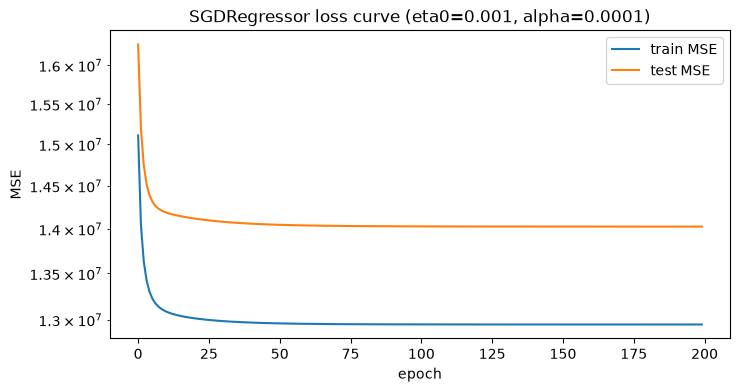

In [10]:
sgd, hist = train_sgd(best_sgd.eta0, best_sgd.alpha, int(best_sgd.epochs), record=True)
hist = np.array(hist)
plt.figure(figsize=(8, 4))
plt.plot(hist[:, 0], label="train MSE"); plt.plot(hist[:, 1], label="test MSE")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.yscale("log")
plt.title(f"SGDRegressor loss curve (eta0={best_sgd.eta0}, alpha={best_sgd.alpha})"); plt.legend(); plt.show()

**Loss curve.** Train and test MSE fall together and flatten; the gap between them stays small, so the linear model is not over-fitting — its remaining error is bias (the relationship is not purely linear).